# Function 2: pooled cohort exploration

**Side quest — 20 October 2026.** A copy of the [Week 4 notebook](../../../../../notebooks/Function_2/Week_04/exploration.ipynb),
using **18 observations**: 10 shared initial points,
3 confirmed own returns and **5 additional peer records**.
The methods, target treatments and search settings are retained. Peer data are
published reports, not independently verified portal returns. See the
[dataset audit](../../../dataset-audit.json) for exact sources and exclusions.

Week 4 has already been submitted. Any original coverage plan is a historical
reference; any newly calculated suggestion here is hypothetical. This pooled
snapshot includes records collected later, so its validation is not a forecast
made before the original Week 3 return. Query-budget numbers refer to the
original start of Week 4 and confer no additional evaluation allowance.


## Function description and cohort clues

**Course description, paraphrased.** Tune two inputs to improve a noisy log-likelihood score. Multiple local peaks may occur; the objective is to maximise the returned score.

Source: [Mini-lesson 12.8: function descriptions](https://classroom.emeritus.org/courses/18642/modules/items/3237303), reviewed
20 October 2026. The notes below interpret the fixed cohort snapshot collected
on that date. Peer outputs are published reports, not independently verified
portal returns. Every official objective remains maximisation of signed y.

### What the cohort observations suggest

The **18 observations** provide support near **x1 = 0.67–0.73**. The three highest
scores occur at `(0.702637, 0.926564)` → **0.611205**,
`(0.690829, 0.926564)` → **0.592732**, and
`(0.665800, 0.123969)` → **0.538996**.

High scores at very different x2 values suggest two potentially good
neighbourhoods. A continuous ridge and separate high regions are both plausible;
the observations do not establish a high ridge all the way between them. The
upper neighbourhood has more nearby published support than the lower one.

The brief explicitly allows noise. A lower nearby return can reflect noise,
real variation or both; there are no repeated full input combinations here to
measure repeat-evaluation noise independently. The supplied best remains the
pooled incumbent.

### Exploration implication

Investigate whether the upper and lower high regions connect, for example by
varying x2 while keeping x1 near 0.7. Keep the possibility of additional local
peaks open. Model the supplied signed score directly; it already represents a
log-likelihood, so another logarithm is not required by the description.

These patterns describe selected observations, not controlled causal effects or a known true surface. Exploration suggestions are hypotheses for the side quest, not submissions.


In [1]:
# Imports & shared helpers
import numpy as np
import pandas as pd
from pathlib import Path
import sys

# Find Shared from any function/week folder inside notebooks.
shared_dir = next(
    (folder / "Shared"
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "plot_helpers.py").is_file()),
    None,
)
if shared_dir is None:
    raise FileNotFoundError(
        "Cannot find Shared/plot_helpers.py above the working directory. "
        "Run this notebook from within the notebooks folder."
    )
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from plot_helpers import (
    PLOT_CONFIG, plot_observed_terrain,
    plot_sampling_gaps, plot_fixed_exploration_progression,
    plot_output_number_line,
)
from output_helpers import summarise_output_observations


In [2]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "exploration.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "exploration.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)



In [3]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\side-quests\cohort-2026-10-20\notebooks\Function_2\Week_04\observations.csv


In [4]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'y'], dtype='str')


In [5]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
y                 0
dtype: int64


In [6]:
# Prepare observation labels for the exploration plots
plot_data = data.copy()
plot_data["rank"] = (
    plot_data["y"]
    .rank(ascending=False, method="min")
    .astype(int)
)

In [7]:
# Splitting our data into inputs X and outputs y
output_column = "y"
input_columns = ["x1", "x2"]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [8]:
# So now we have:

# data	       = Observations as loaded from the CSV
# X, y	       = Inputs and outputs selected from those observations
# plot_data	   = A separate copy enriched for the exploration plots

In [9]:
# Review the latest recorded submission against earlier observed outputs.
output_review = summarise_output_observations(
    data,
    input_columns=input_columns,
    output_column=output_column,
)
print(output_review["report"])


Latest recorded submission: round 3 (1 new output).
Compared with 17 earlier observations (18 outputs in total).
Earlier output range: [-0.065624, 0.611205215761].

round-03: y = 0.156096371964 (positive); rank 10/18 (1 = highest output).
Inputs: x1 = 0.835565, x2 = 0.232911
Within the earlier output range.


## Observed outputs

A linear number line suits Function 2's moderate output range. The latest submission is starred;
zero is an ordinary point on this scale.


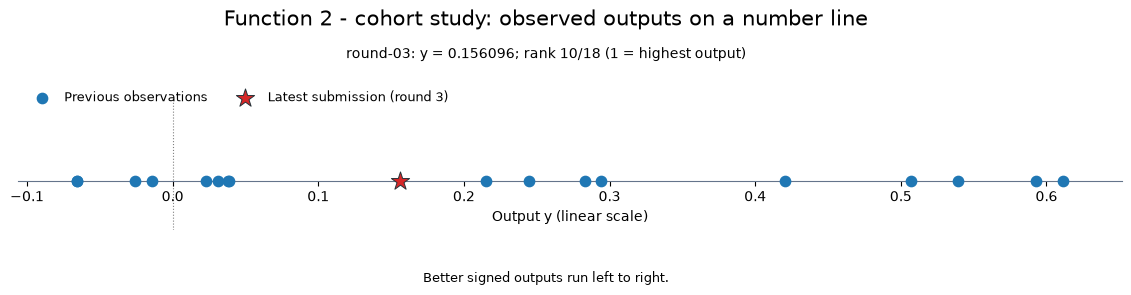

In [10]:
plot_output_number_line(
    output_review,
    title="Function 2 - cohort study: observed outputs on a number line",
    save_to=figures / "output-number-line.png",
)

## Observed ranks and sampling gaps

Numbers are observed output ranks (1 = highest). The background shows distance to the nearest observed point.


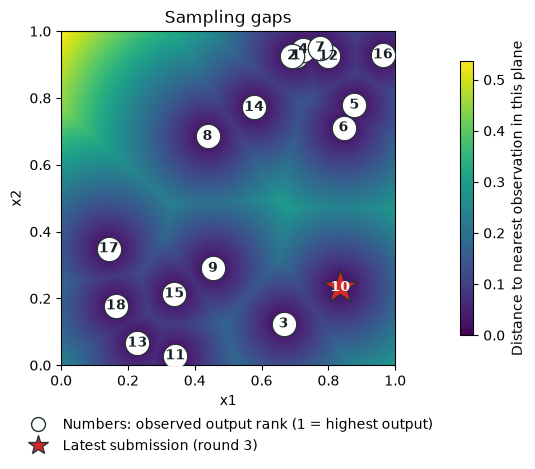

In [11]:
# Visualisation of the input-space coverage of the observations so far.
sampling_gaps_fig = plot_sampling_gaps(
    plot_data, highlight=output_review["latest_mask"],
    highlight_label=f"Latest submission (round {output_review['latest_round']})",
)
sampling_gaps_fig.set_size_inches(sampling_gaps_fig.get_size_inches() * 0.75)
sampling_gaps_fig.savefig(figures / "sampling-gaps.png", dpi=160)
sampling_gaps_fig


## Observed-output terrain

Use `x1` and `x2` as the ground plane and the measured output `y` as height.
Function 2's moderate output range suits a linear scale; the vertical aspect ratio of `0.16` flattens the relief.
Black markers are measurements; the gold diamond identifies the highest observed output.
The triangular faces simply join measured heights. They are a visual interpolation, not a fitted regression or a known function surface.
Blank areas lie outside the sampled region. Drag to rotate, scroll to zoom, and use **Reset view** to restore the initial orientation and zoom.


In [12]:
# Function 2 uses raw output heights, with the same shared terrain renderer.
terrain_y = y.to_numpy(dtype=float)
terrain_html = figures / "observed-output-terrain.html"
terrain_fig = plot_observed_terrain(
    X.to_numpy(), terrain_y,
    title=f"Function 2: observed-output terrain ({len(terrain_y)} samples)",
    relief=0.16, save_to=terrain_html,
    width=850, height=560, camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)
print(f"Raw output heights: {terrain_y.min():.4f} to {terrain_y.max():.4f} ({len(terrain_y)} observations).")
print(f"Interactive browser copy: {terrain_html}")
terrain_fig.show(config={**PLOT_CONFIG, "responsive": False})


Raw output heights: -0.0656 to 0.6112 (18 observations).
Interactive browser copy: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\side-quests\cohort-2026-10-20\notebooks\Function_2\Week_04\figures\observed-output-terrain.html


## Next query(s)

In [13]:
# Fixed Week 2 plan, preserved at full precision; no optimisation is run.
planned_queries = pd.DataFrame(
    [[0.22823414192856306, 0.06664413600559765], [0.8355651699511926, 0.23291097243365763], [0.17953980688500848, 0.8087368655610445]],
    columns=input_columns,
)

# The saved sequence starts in Week 2; keep only this week's unevaluated remainder.
current_week = int(week_dir.name.removeprefix("Week_"))
coverage_queries = planned_queries.iloc[current_week - 2:].copy()


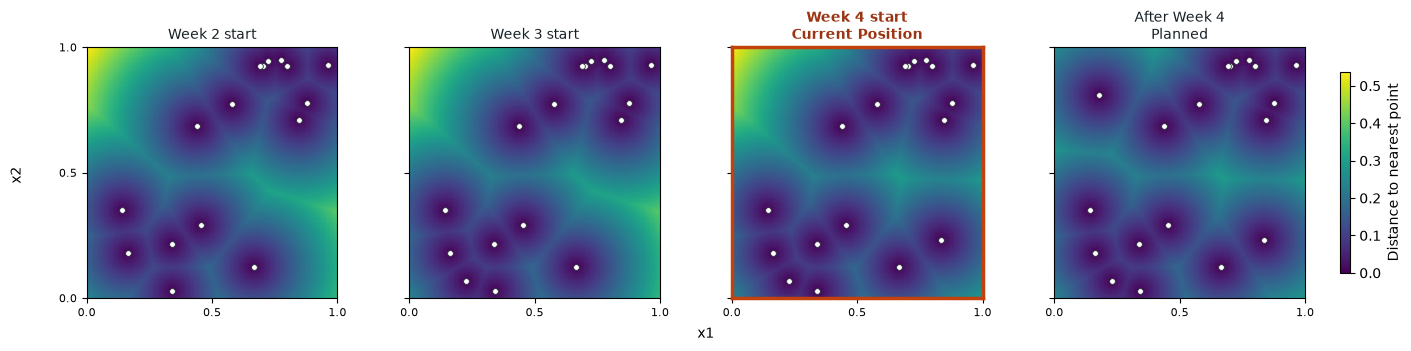

In [14]:
# Geometric comparison: peer points are a fixed background in every panel.
# This is not a reconstruction of when those points became available.
progression_data = data.copy()
progression_data.loc[progression_data['observation_id'].str.startswith('peer-'), 'source_round'] = 0
plot_fixed_exploration_progression(
    progression_data, planned_queries,
    current_week=current_week,
    save_to=figures / "fixed-exploration-progression.png",
)

In [15]:
# Copy the portal-ready input from the row for the required week.
remaining_queries = coverage_queries.copy()
remaining_queries.index = pd.Index(
    range(current_week, current_week + len(remaining_queries)), name="Week",
)
remaining_queries["Portal input"] = [
    "-".join(f"{value:.6f}" for value in point)
    for point in coverage_queries.to_numpy()
]
remaining_queries.style.format({column: "{:.6f}" for column in input_columns})

,x1,x2,Portal input
Week,,,
4,0.179540,0.808737,0.179540-0.808737


## Continue with model predictions (for fun)

This optional continuation is for learning and experimentation. The saved exploration plan
above remains the original Week 4 reference plan.

[Model predictions](model_predictions.ipynb) includes regression comparisons, GP curves and uncertainty,
contour maps and a hypothetical model-led next query. It loads this week's observations independently.


The fixed-plan progression treats all published peer inputs as a background and adds the original planned points in order. Other exploration plots use the full pooled data. This geometric comparison does not reconstruct historical data availability.